# TD1 – Introduction et apprenabilité
## Apprentissage PAC vs PAC agnostique : étude expérimentale avec des classifieurs à seuil

**Auteur :** *Sylvain Xayphrarath*

**Objectif.** Illustrer expérimentalement la différence entre les cadres PAC (réalisable) et PAC agnostique.
Nous implémentons un algorithme de minimisation du risque empirique (ERM) pour la classe des classifieurs à seuil sur $\mathcal{X}=[0,1]$,
d'abord sans bruit (cas réalisable), puis avec du bruit sur les étiquettes (cas agnostique).

**Cadre.**
- Cible : $f_\theta(x)=\mathbf 1[x>\theta]$, avec $\theta\in(0,1)$ inconnu de l'apprenant.
- Classe d'hypothèses : $\mathcal H=\{h_t : t\in[0,1]\}$, $h_t(x)=\mathbf 1[x>t]$ (dimension de Vapnik-Chervonenkis égale à 1).
- Entrées : $x\sim\mathcal U[0,1]$. Étiquettes dans le cas réalisable : $y=f_\theta(x)$. Dans le cas agnostique : $y=f_\theta(x)$ inversée indépendamment avec probabilité $\eta$.
- Seul `numpy` est utilisé pour l'apprentissage ; `matplotlib` sert aux graphiques.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---------------- Paramètres expérimentaux (nos propres choix) ----------------
THETA  = 0.37                      # vrai seuil
EPS    = 0.05                      # paramètre de précision epsilon
DELTA  = 0.05                      # paramètre de confiance delta
ETA    = 0.15                      # taux de bruit sur les étiquettes (cas agnostique)
M_LIST = [5, 10, 20, 50, 100, 200] # tailles d'échantillon demandées dans le TD
N_REP  = 1000                      # nombre de répétitions par taille
N_TEST = 200_000                   # taille de l'échantillon de test indépendant
SEED   = 2026

print(f"theta={THETA}, eps={EPS}, delta={DELTA}, eta={ETA}, répétitions={N_REP}, taille du test={N_TEST}")

theta=0.37, eps=0.05, delta=0.05, eta=0.15, répétitions=1000, taille du test=200000


**Choix des paramètres.**
- $\theta=0{,}37$ : pas trop proche des bords (le seuil appris peut se tromper des deux côtés) et différent de $0{,}5$ (pour éviter un cas symétrique particulier).
- $\varepsilon=0{,}05$ et $\delta=0{,}05$ : on veut un classifieur avec au plus 5 % d'erreur avec une probabilité d'au moins 95 %.
- $\eta=0{,}15$ : un bruit modéré mais bien visible (la meilleure erreur possible vaut alors 15 %).
- 1000 répétitions : l'écart-type d'une probabilité estimée est au plus $\sqrt{0{,}25/1000}\approx 0{,}016$.
- 200 000 points de test : l'écart-type sur une erreur de test est inférieur à $0{,}0012$.

## 1. Génération des données

In [3]:
def target(x, theta=THETA):
    """Fonction cible f_theta(x) = 1[x > theta]."""
    return (x > theta).astype(int)


def generate_data(m, theta=THETA, eta=0.0, rng=None):
    """Tire m points uniformément dans [0,1].
    Étiquettes : f_theta(x), chacune inversée indépendamment avec probabilité eta (eta=0 -> cas réalisable)."""
    rng = np.random.default_rng() if rng is None else rng
    X = rng.uniform(0.0, 1.0, size=m)
    y = target(X, theta)
    flips = rng.random(m) < eta          # toujours tiré : à graine égale, X est identique quel que soit eta
    y = np.where(flips, 1 - y, y)
    return X, y


rng_demo = np.random.default_rng(SEED)
datasets_real = {m: generate_data(m, THETA, 0.0, rng_demo) for m in M_LIST}
datasets_agn  = {m: generate_data(m, THETA, ETA, rng_demo) for m in M_LIST}

for m in M_LIST:
    X, y = datasets_agn[m]
    expected = target(X)
    print(f"m={m:4d} | réalisable : positifs={datasets_real[m][1].mean():.2f} "
          f"| agnostique : positifs={y.mean():.2f}, étiquettes inversées={np.mean(y != expected):.2f}")

m=   5 | réalisable : positifs=0.60 | agnostique : positifs=0.80, étiquettes inversées=0.00
m=  10 | réalisable : positifs=0.70 | agnostique : positifs=0.70, étiquettes inversées=0.10
m=  20 | réalisable : positifs=0.65 | agnostique : positifs=0.80, étiquettes inversées=0.20
m=  50 | réalisable : positifs=0.66 | agnostique : positifs=0.66, étiquettes inversées=0.08
m= 100 | réalisable : positifs=0.63 | agnostique : positifs=0.64, étiquettes inversées=0.17
m= 200 | réalisable : positifs=0.64 | agnostique : positifs=0.57, étiquettes inversées=0.20


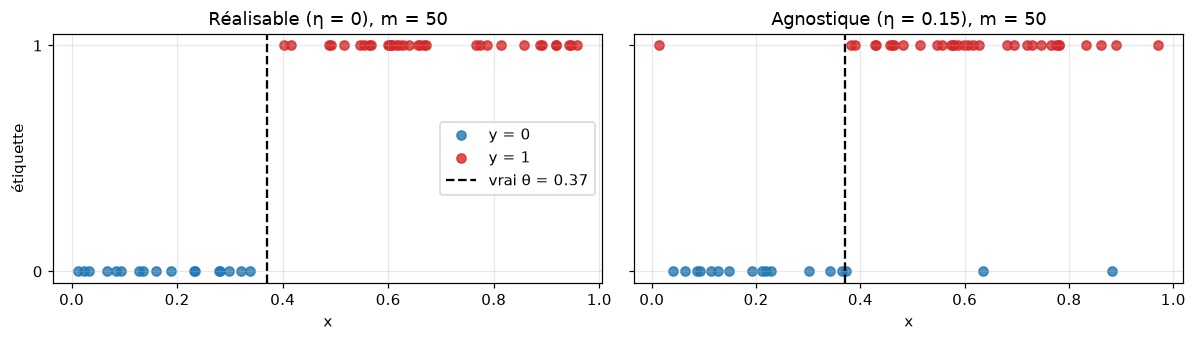

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (name, data) in zip(axes, [("Réalisable (η = 0)", datasets_real), (f"Agnostique (η = {ETA})", datasets_agn)]):
    X, y = data[50]
    ax.scatter(X[y == 0], y[y == 0], c="tab:blue", label="y = 0", alpha=0.8)
    ax.scatter(X[y == 1], y[y == 1], c="tab:red", label="y = 1", alpha=0.8)
    ax.axvline(THETA, color="k", ls="--", label=f"vrai θ = {THETA}")
    ax.set_title(f"{name}, m = 50"); ax.set_xlabel("x"); ax.set_yticks([0, 1])
axes[0].set_ylabel("étiquette"); axes[0].legend(loc="center right")
plt.tight_layout(); plt.show()

**Commentaire.** Dans le cas réalisable, les points sont parfaitement séparés par la droite verticale $x=\theta$.
Avec du bruit, quelques points se trouvent du « mauvais » côté de $\theta$ : aucun seuil ne peut plus classer correctement tous les points.

## 2. Implémentation de l'ERM

**Stratégie.** Un classifieur à seuil $h_t$ ne change ses prédictions sur les points d'apprentissage que lorsque $t$ franchit
l'un d'eux. Il suffit donc de considérer $m+1$ hypothèses candidates : on trie les points
$x_{(1)}<\dots<x_{(m)}$, et $h^{(k)}$ prédit $0$ sur les $k$ plus petits points et $1$ sur les autres, pour $k=0,\dots,m$.
Son erreur empirique vaut

$$ \hat L_S(h^{(k)}) = \frac1m\Big(\#\{i\le k : y_{(i)}=1\} + \#\{i>k : y_{(i)}=0\}\Big), $$

que l'on calcule pour tous les $k$ à la fois avec des sommes cumulées. On choisit le $k$ d'erreur minimale (ERM),
donc l'algorithme coûte $O(m\log m)$ (le tri). Plusieurs seuils peuvent avoir la même erreur empirique
(dans le cas réalisable, tout $t$ situé entre le plus grand point négatif et le plus petit point positif est cohérent avec les données) :
on renvoie le **milieu** de l'intervalle correspondant, et on départage les $k$ à égalité en prenant le premier.

In [5]:
def erm_threshold(X, y):
    """ERM sur les classifieurs à seuil h_t(x) = 1[x > t].
    Renvoie (t_chapeau, erreur_empirique)."""
    m = len(X)
    order = np.argsort(X)
    xs, ys = X[order], y[order]

    ones_cum  = np.concatenate(([0], np.cumsum(ys)))        # nb de positifs parmi les k plus petits points
    zeros_cum = np.concatenate(([0], np.cumsum(1 - ys)))    # nb de négatifs parmi les k plus petits points
    # k points prédits 0 : erreurs = positifs parmi eux + négatifs parmi les m-k autres
    errors = ones_cum + (zeros_cum[-1] - zeros_cum)

    k = int(np.argmin(errors))
    lo = 0.0 if k == 0 else xs[k - 1]
    hi = 1.0 if k == m else xs[k]
    return 0.5 * (lo + hi), errors[k] / m


def predict(X, t):
    return (X > t).astype(int)


def empirical_error(X, y, t):
    return float(np.mean(predict(X, t) != y))


# ---- Vérification : l'ERM doit coïncider avec une recherche exhaustive sur une grille fine de seuils ----
rng_check = np.random.default_rng(0)
for eta in [0.0, 0.2]:
    for m in [5, 20, 100]:
        X, y = generate_data(m, THETA, eta, rng_check)
        t_hat, e_hat = erm_threshold(X, y)
        grid = np.linspace(0, 1, 20001)
        brute = min(empirical_error(X, y, t) for t in grid)
        assert abs(empirical_error(X, y, t_hat) - e_hat) < 1e-12   # l'erreur renvoyée est bien celle de h_t_hat
        assert e_hat <= brute + 1e-12                              # aucun seuil de la grille ne fait mieux que l'ERM
print("Vérifications de l'ERM réussies.")

Vérifications de l'ERM réussies.


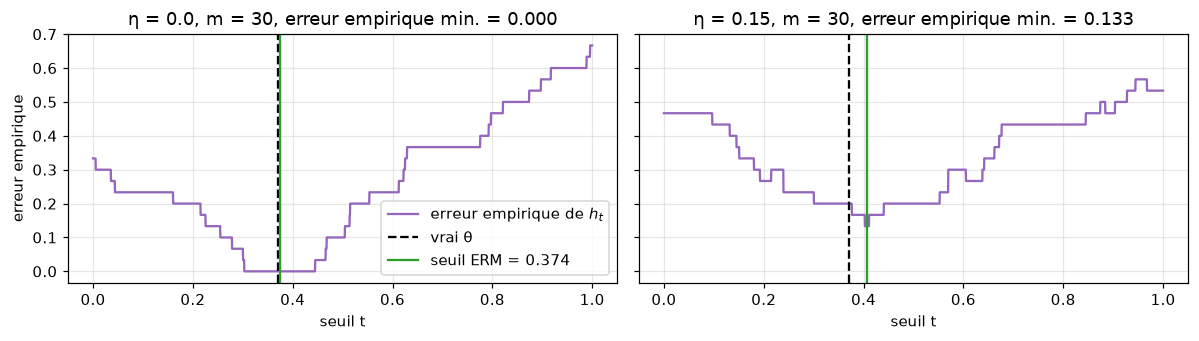

In [6]:
# Paysage de l'erreur empirique L_S(h_t) en fonction de t, pour un jeu de données réalisable et un jeu bruité (m = 30)
rng_vis = np.random.default_rng(7)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
grid = np.linspace(0, 1, 2000)
for ax, eta in zip(axes, [0.0, ETA]):
    X, y = generate_data(30, THETA, eta, rng_vis)
    curve = [empirical_error(X, y, t) for t in grid]
    t_hat, e_hat = erm_threshold(X, y)
    ax.plot(grid, curve, color="tab:purple", label="erreur empirique de $h_t$")
    ax.axvline(THETA, color="k", ls="--", label="vrai θ")
    ax.axvline(t_hat, color="tab:green", label=f"seuil ERM = {t_hat:.3f}")
    ax.set_title(f"η = {eta}, m = 30, erreur empirique min. = {e_hat:.3f}")
    ax.set_xlabel("seuil t")
axes[0].set_ylabel("erreur empirique"); axes[0].legend()
plt.tight_layout(); plt.show()

**Commentaire.** Sans bruit, la courbe d'erreur empirique présente une vallée plate à zéro qui contient $\theta$ :
l'ERM renvoie le milieu de cette vallée. Avec du bruit, la courbe est irrégulière et son minimum est strictement positif ;
l'ERM choisit le point le plus bas, qui n'est en général *pas* exactement $\theta$ (il ajuste une partie des étiquettes bruitées).

## 3. Évaluation des performances

Pour un seuil appris $\hat t$, on compare :
- l'**erreur empirique** $L_S(h_{\hat t})$ sur l'échantillon d'apprentissage ;
- l'**erreur vraie** $L_{\mathcal D}(h_{\hat t})$, estimée sur un grand échantillon de test indépendant tiré selon la *même* distribution
  (avec bruit sur les étiquettes dans le cas agnostique) ;
- à titre de référence, l'**erreur exacte**, disponible ici sous forme fermée. Avec $\Delta=|\hat t-\theta|$ (probabilité que $h_{\hat t}$ et $f_\theta$ diffèrent) :
  $L_{\mathcal D}(h_{\hat t})=\Delta$ dans le cas réalisable et $(1-\eta)\Delta+\eta(1-\Delta)=\eta+(1-2\eta)\Delta$ avec bruit.

In [7]:
def exact_true_error(t, theta=THETA, eta=0.0):
    """Erreur exacte de h_t sous la distribution (éventuellement bruitée)."""
    d = np.abs(np.asarray(t) - theta)
    return eta + (1 - 2 * eta) * d


def excess_risk(t, theta=THETA, eta=0.0):
    """L_D(h_t) - min_h L_D(h) : la quantité contrôlée par l'apprentissage PAC (agnostique). La meilleure erreur vaut eta."""
    return exact_true_error(t, theta, eta) - eta


rng_test = np.random.default_rng(SEED + 1)

def make_test_set(eta):
    return generate_data(N_TEST, THETA, eta, rng_test)

print(f"{'cadre':<14}{'m':>5}{'t_chap':>9}{'err. appr.':>12}{'err. test':>11}{'err. exacte':>13}{'écart (test-appr.)':>20}")
rows = {}
for label, eta, data in [("réalisable", 0.0, datasets_real), ("agnostique", ETA, datasets_agn)]:
    Xte, yte = make_test_set(eta)
    for m in M_LIST:
        X, y = data[m]
        t_hat, e_emp = erm_threshold(X, y)
        e_test = empirical_error(Xte, yte, t_hat)
        e_exact = float(exact_true_error(t_hat, THETA, eta))
        rows[(label, m)] = (t_hat, e_emp, e_test, e_exact)
        print(f"{label:<14}{m:>5}{t_hat:>9.3f}{e_emp:>12.3f}{e_test:>11.3f}{e_exact:>13.3f}{e_test - e_emp:>20.3f}")

cadre             m   t_chap  err. appr.  err. test  err. exacte  écart (test-appr.)
réalisable        5    0.363       0.000      0.007        0.007               0.007
réalisable       10    0.394       0.000      0.023        0.024               0.023
réalisable       20    0.389       0.000      0.019        0.019               0.019
réalisable       50    0.370       0.000      0.001        0.000               0.001
réalisable      100    0.393       0.000      0.022        0.023               0.022
réalisable      200    0.372       0.000      0.002        0.002               0.002
agnostique        5    0.380       0.000      0.156        0.157               0.156
agnostique       10    0.398       0.100      0.169        0.169               0.069
agnostique       20    0.003       0.200      0.407        0.407               0.207
agnostique       50    0.378       0.060      0.155        0.155               0.095
agnostique      100    0.310       0.150      0.192        0.192 

**Commentaire.** L'erreur de test coïncide avec l'erreur vraie exacte à environ $10^{-3}$ près, ce qui valide l'estimation par échantillon de test
(et nous permet d'utiliser la forme fermée dans les expériences répétées ci-dessous).
- *Réalisable :* l'erreur empirique vaut toujours $0$, alors que l'erreur vraie est positive mais petite et tend à diminuer quand $m$ augmente.
  L'erreur empirique est donc une estimation optimiste (biaisée) de l'erreur vraie.
- *Agnostique :* l'erreur empirique n'est pas nulle, et l'erreur vraie reste au-dessus du niveau de bruit $\eta=0{,}15$
  (aucun classifieur ne peut faire mieux que $\eta$ en moyenne). Un seul tirage est assez variable ; on moyenne donc maintenant sur de nombreuses répétitions.

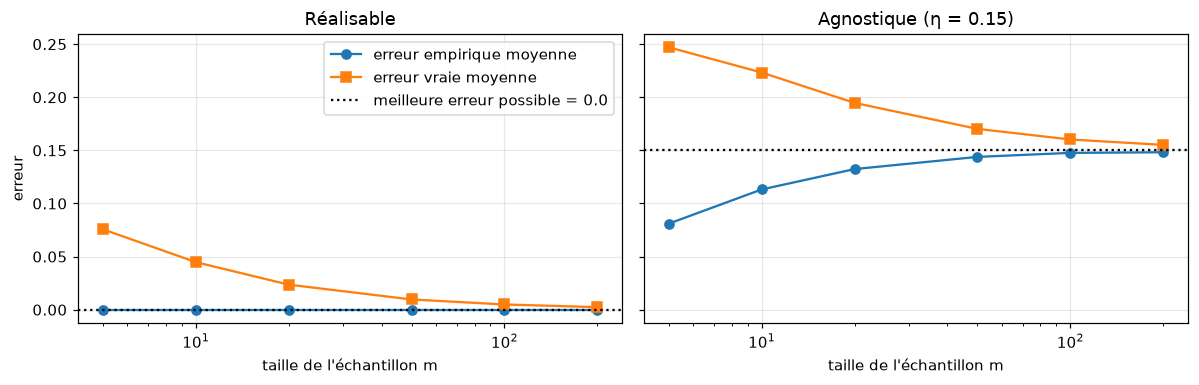

    m |  réal.: emp réal.: vraie |  agn.: emp agn.: vraie   écart
    5 |      0.0000       0.0757 |     0.0810      0.2470  0.1660
   10 |      0.0000       0.0448 |     0.1132      0.2233  0.1101
   20 |      0.0000       0.0236 |     0.1324      0.1947  0.0623
   50 |      0.0000       0.0097 |     0.1439      0.1702  0.0264
  100 |      0.0000       0.0049 |     0.1477      0.1603  0.0126
  200 |      0.0000       0.0024 |     0.1482      0.1552  0.0069


In [8]:
def run_experiment(m_list, eta, n_rep, seed, theta=THETA):
    """Répète « tirer un échantillon d'apprentissage -> lancer l'ERM » n_rep fois pour chaque taille de m_list.
    Renvoie les tableaux t_hat et emp_err de forme (len(m_list), n_rep)."""
    rng = np.random.default_rng(seed)
    t_hat = np.zeros((len(m_list), n_rep))
    emp = np.zeros((len(m_list), n_rep))
    for i, m in enumerate(m_list):
        for r in range(n_rep):
            X, y = generate_data(m, theta, eta, rng)
            t_hat[i, r], emp[i, r] = erm_threshold(X, y)
    return t_hat, emp


t_real, emp_real = run_experiment(M_LIST, 0.0, N_REP, SEED)
t_agn,  emp_agn  = run_experiment(M_LIST, ETA, N_REP, SEED)

true_real = exact_true_error(t_real, THETA, 0.0)
true_agn  = exact_true_error(t_agn, THETA, ETA)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, name, emp, tru, eta in [(axes[0], "Réalisable", emp_real, true_real, 0.0),
                                (axes[1], f"Agnostique (η = {ETA})", emp_agn, true_agn, ETA)]:
    ax.plot(M_LIST, emp.mean(axis=1), "o-", label="erreur empirique moyenne")
    ax.plot(M_LIST, tru.mean(axis=1), "s-", label="erreur vraie moyenne")
    ax.axhline(eta, color="k", ls=":", label=f"meilleure erreur possible = {eta}")
    ax.set_xscale("log"); ax.set_xlabel("taille de l'échantillon m"); ax.set_title(name)
axes[0].set_ylabel("erreur"); axes[0].legend()
plt.tight_layout(); plt.show()

print(f"{'m':>5} | {'réal.: emp':>11}{'réal.: vraie':>13} | {'agn.: emp':>10}{'agn.: vraie':>12}{'écart':>8}")
for i, m in enumerate(M_LIST):
    print(f"{m:>5} | {emp_real[i].mean():>11.4f}{true_real[i].mean():>13.4f} | "
          f"{emp_agn[i].mean():>10.4f}{true_agn[i].mean():>12.4f}{true_agn[i].mean() - emp_agn[i].mean():>8.4f}")

**Commentaire.**
- *Réalisable :* l'erreur empirique est exactement 0 pour tout $m$, et l'erreur vraie décroît vers 0 quand $m$ augmente.
- *Agnostique :* l'erreur vraie décroît vers $\eta=0{,}15$ **par le haut**, tandis que l'erreur empirique reste **en dessous** de $\eta$ et
  augmente vers cette valeur. L'écart entre les deux (le surapprentissage de l'ERM sur les étiquettes bruitées) est grand pour les petits $m$
  et se referme quand $m$ grandit. Ce qui peut être appris, c'est donc « aussi bien que la meilleure hypothèse de $\mathcal H$ », et non « parfaitement ».

## 4. Vérification expérimentale de l'apprentissage PAC (cas réalisable)

Garantie PAC : pour tous $\varepsilon,\delta$, il existe $m(\varepsilon,\delta)$ tel que pour tout $m\ge m(\varepsilon,\delta)$,
$\Pr_S\big(L(h_S)>\varepsilon\big)\le\delta$. On estime $\Pr(L(h_S)>\varepsilon)$ avec $\varepsilon=0{,}05$ par la proportion des 1000
répétitions dans lesquelles l'erreur vraie dépasse $\varepsilon$.

Pour cette classe, il existe une borne théorique simple : si un seuil cohérent $\hat t$ a une erreur supérieure à $\varepsilon$,
l'intervalle entre $\theta$ et $\hat t$ (de masse de probabilité $>\varepsilon$) ne contient aucun point d'apprentissage, ce qui arrive avec une probabilité
au plus égale à $(1-\varepsilon)^m$ de chaque côté de $\theta$. Donc

$$\Pr\big(L(h_S)>\varepsilon\big)\le 2(1-\varepsilon)^m \le \delta \quad\text{dès que}\quad m\ge \frac{\ln(2/\delta)}{\varepsilon}.$$

Taille d'échantillon théorique pour eps=0.05, delta=0.05 : m >= ln(2/delta)/eps = 74

    m  Pr(L>eps) estimée  écart-type   borne 2(1-eps)^m  <= delta ?
    5              0.587       0.016              1.000       False
   10              0.337       0.015              1.000       False
   20              0.121       0.010              0.717       False
   50              0.007       0.003              0.154        True
  100              0.000       0.000              0.012        True
  200              0.000       0.000              0.000        True


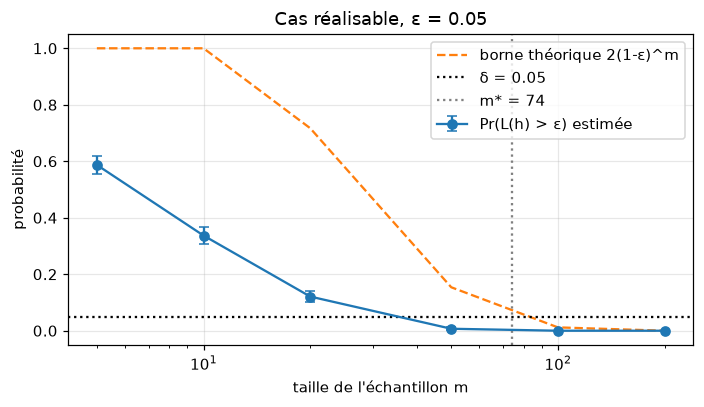

In [9]:
def prob_error_exceeds(errors, eps):
    """Proportion de répétitions où l'erreur dépasse eps, et son écart-type. errors : (n_tailles, n_rep)."""
    p = (errors > eps).mean(axis=1)
    se = np.sqrt(p * (1 - p) / errors.shape[1])
    return p, se


p_real, se_real = prob_error_exceeds(true_real, EPS)
bound = np.minimum(1.0, 2 * (1 - EPS) ** np.array(M_LIST))
m_star = int(np.ceil(np.log(2 / DELTA) / EPS))
print(f"Taille d'échantillon théorique pour eps={EPS}, delta={DELTA} : m >= ln(2/delta)/eps = {m_star}\n")
print(f"{'m':>5}{'Pr(L>eps) estimée':>19}{'écart-type':>12}{'borne 2(1-eps)^m':>19}{'<= delta ?':>12}")
for m, p, se, b in zip(M_LIST, p_real, se_real, bound):
    print(f"{m:>5}{p:>19.3f}{se:>12.3f}{b:>19.3f}{str(bool(p <= DELTA)):>12}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(M_LIST, p_real, yerr=1.96 * se_real, fmt="o-", capsize=3, label="Pr(L(h) > ε) estimée")
ax.plot(M_LIST, bound, "--", color="tab:orange", label="borne théorique 2(1-ε)^m")
ax.axhline(DELTA, color="k", ls=":", label=f"δ = {DELTA}")
ax.axvline(m_star, color="gray", ls=":", label=f"m* = {m_star}")
ax.set_xscale("log"); ax.set_xlabel("taille de l'échantillon m"); ax.set_ylabel("probabilité")
ax.set_title(f"Cas réalisable, ε = {EPS}"); ax.legend()
plt.tight_layout(); plt.show()

**Commentaire.** La probabilité d'obtenir une « mauvaise » hypothèse ($L>\varepsilon$) décroît rapidement (de façon exponentielle) avec $m$ : elle est
grande pour de tout petits échantillons (environ 0,6 pour $m=5$), puis passe sous $\delta=0{,}05$ dès $m=50$ dans notre grille, c'est-à-dire plus tôt que la
taille théorique $m^*=74$, car la borne n'est qu'un majorant (valable pour tout $\theta$ et tout apprenant cohérent).
Les estimations restent toujours sous la courbe théorique (aux fluctuations d'échantillonnage près).
C'est exactement l'énoncé PAC : avec assez d'exemples, l'ERM est probablement (probabilité $\ge 1-\delta$) approximativement ($L\le\varepsilon$) correct.

## 5. Du PAC au PAC agnostique

Avec du bruit sur les étiquettes, la cible n'appartient plus à $\mathcal H$. Le bon objectif n'est plus $L(h)\le\varepsilon$ mais
$L_{\mathcal D}(h)\le \min_{h'\in\mathcal H}L_{\mathcal D}(h')+\varepsilon$. Ici $\min_{h'}L_{\mathcal D}(h')=\eta$ (atteint en $t=\theta$), donc la quantité pertinente est le
**risque en excès** $L_{\mathcal D}(h_S)-\eta=(1-2\eta)|\hat t-\theta|$.

### 5.1 L'erreur empirique peut-elle encore atteindre zéro ?

    m  réalisable : P(emp=0)  agnostique : P(emp=0)   (1-eta)^m  err. emp. moy.
    5                  1.000                  0.632       0.444           0.081
   10                  1.000                  0.264       0.197           0.113
   20                  1.000                  0.041       0.039           0.132
   50                  1.000                  0.000       0.000           0.144
  100                  1.000                  0.000       0.000           0.148
  200                  1.000                  0.000       0.000           0.148


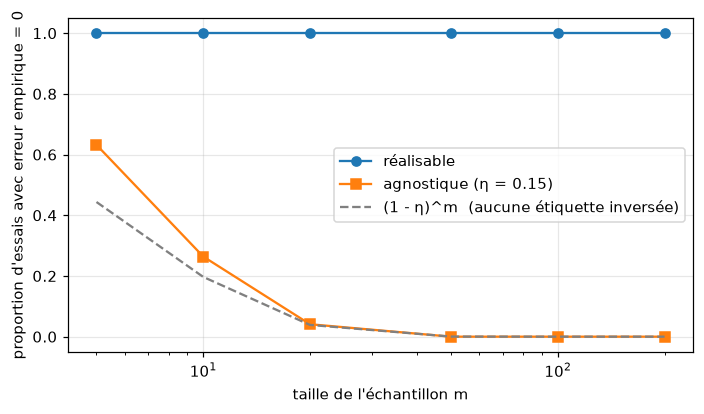

In [10]:
frac_zero = (emp_agn == 0).mean(axis=1)
frac_zero_real = (emp_real == 0).mean(axis=1)
p_no_flip = (1 - ETA) ** np.array(M_LIST)

print(f"{'m':>5}{'réalisable : P(emp=0)':>23}{'agnostique : P(emp=0)':>23}{'(1-eta)^m':>12}{'err. emp. moy.':>16}")
for i, m in enumerate(M_LIST):
    print(f"{m:>5}{frac_zero_real[i]:>23.3f}{frac_zero[i]:>23.3f}{p_no_flip[i]:>12.3f}{emp_agn[i].mean():>16.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(M_LIST, frac_zero_real, "o-", label="réalisable")
ax.plot(M_LIST, frac_zero, "s-", label=f"agnostique (η = {ETA})")
ax.plot(M_LIST, p_no_flip, "--", color="gray", label="(1 - η)^m  (aucune étiquette inversée)")
ax.set_xscale("log"); ax.set_xlabel("taille de l'échantillon m"); ax.set_ylabel("proportion d'essais avec erreur empirique = 0")
ax.legend(); plt.tight_layout(); plt.show()

**Commentaire.** Dans le cas réalisable, l'erreur empirique est nulle dans 100 % des essais. Avec du bruit, elle peut encore être nulle pour de très petits $m$
(par exemple quand aucune étiquette, ou seulement des étiquettes « inoffensives », est inversée), mais cela devient rare dès que $m$ grandit et n'arrive quasiment jamais
pour $m\ge 50$ : la probabilité est de l'ordre de $(1-\eta)^m$. L'erreur empirique de l'ERM converge vers une valeur positive (proche de $\eta$, mais en dessous).
Donc **une erreur empirique nulle ne peut pas servir de critère d'apprentissage** dans le cadre agnostique.

### 5.2 Plus de données améliorent-elles encore la généralisation ?

    m  réalisable Pr(L>eps)  agnostique Pr(L-eta>eps)   excès moyen (agn.)
    5                 0.587                     0.610               0.0970
   10                 0.337                     0.470               0.0733
   20                 0.121                     0.303               0.0447
   50                 0.007                     0.103               0.0202
  100                 0.000                     0.017               0.0103
  200                 0.000                     0.002               0.0052


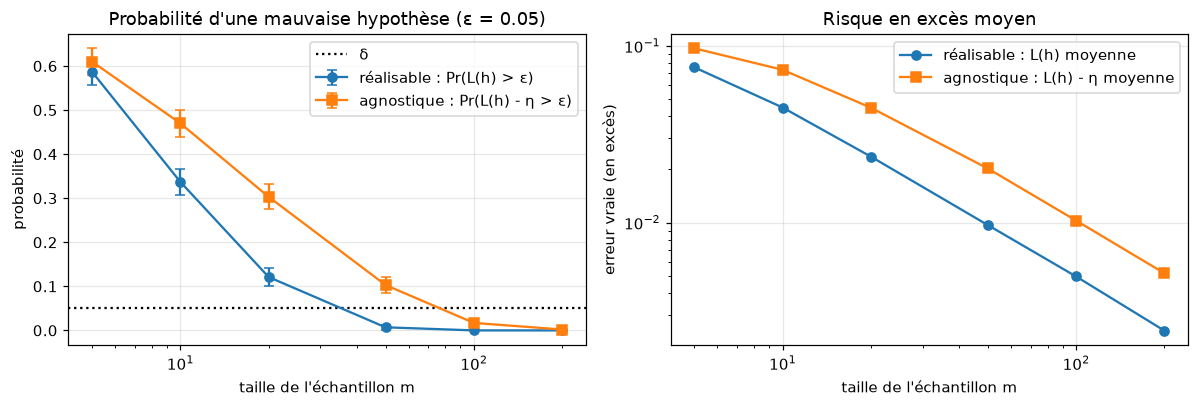

In [11]:
ex_real = excess_risk(t_real, THETA, 0.0)
ex_agn  = excess_risk(t_agn, THETA, ETA)

p_ex_real, se_ex_real = prob_error_exceeds(ex_real, EPS)
p_ex_agn,  se_ex_agn  = prob_error_exceeds(ex_agn, EPS)

print(f"{'m':>5}{'réalisable Pr(L>eps)':>22}{'agnostique Pr(L-eta>eps)':>26}{'excès moyen (agn.)':>21}")
for i, m in enumerate(M_LIST):
    print(f"{m:>5}{p_ex_real[i]:>22.3f}{p_ex_agn[i]:>26.3f}{ex_agn[i].mean():>21.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].errorbar(M_LIST, p_ex_real, yerr=1.96 * se_ex_real, fmt="o-", capsize=3, label="réalisable : Pr(L(h) > ε)")
axes[0].errorbar(M_LIST, p_ex_agn, yerr=1.96 * se_ex_agn, fmt="s-", capsize=3, label="agnostique : Pr(L(h) - η > ε)")
axes[0].axhline(DELTA, color="k", ls=":", label="δ")
axes[0].set_xscale("log"); axes[0].set_xlabel("taille de l'échantillon m"); axes[0].set_ylabel("probabilité"); axes[0].legend()
axes[0].set_title(f"Probabilité d'une mauvaise hypothèse (ε = {EPS})")

axes[1].plot(M_LIST, ex_real.mean(axis=1), "o-", label="réalisable : L(h) moyenne")
axes[1].plot(M_LIST, ex_agn.mean(axis=1), "s-", label="agnostique : L(h) - η moyenne")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("taille de l'échantillon m")
axes[1].set_ylabel("erreur vraie (en excès)"); axes[1].legend(); axes[1].set_title("Risque en excès moyen")
plt.tight_layout(); plt.show()

**Commentaire.** Augmenter $m$ **améliore toujours** la généralisation : le risque en excès $L_{\mathcal D}(h_S)-\eta$ tend vers 0 et la probabilité de
dépasser $\varepsilon$ décroît vers 0. La différence porte sur la **vitesse** : dans le cas agnostique, les courbes sont décalées vers la droite, c'est-à-dire qu'il faut
plus d'exemples pour atteindre la même garantie $(\varepsilon,\delta)$, car les étiquettes bruitées masquent la position de $\theta$
(chaque point porte moins d'information : le risque en excès est multiplié par $(1-2\eta)$ et la position du meilleur seuil est estimée moins précisément).

### 5.3 Influence du niveau de bruit
Pour voir comment la difficulté croît avec $\eta$, on répète l'expérience pour plusieurs taux de bruit et des tailles d'échantillon plus grandes.

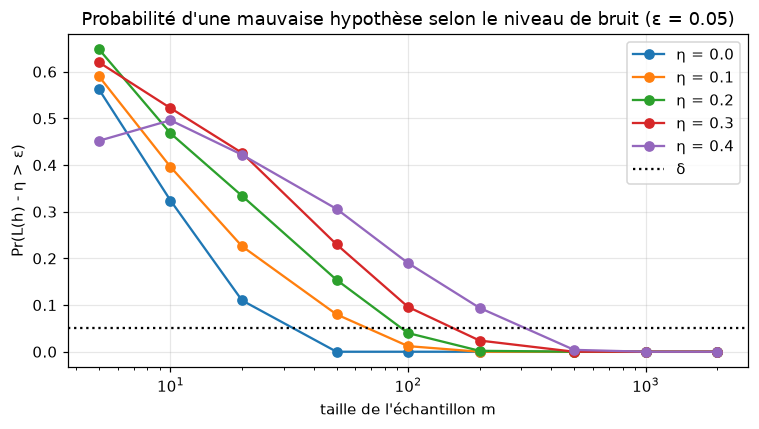

Plus petit m de la grille avec Pr(L - eta > eps) <= delta :
  eta = 0.0 : m = 50
  eta = 0.1 : m = 100
  eta = 0.2 : m = 100
  eta = 0.3 : m = 200
  eta = 0.4 : m = 500


In [12]:
ETAS = [0.0, 0.1, 0.2, 0.3, 0.4]
M_EXT = [5, 10, 20, 50, 100, 200, 500, 1000, 2000]
N_REP_SWEEP = 500

sweep = {}
for eta in ETAS:
    t_e, _ = run_experiment(M_EXT, eta, N_REP_SWEEP, SEED + 10)
    sweep[eta] = prob_error_exceeds(excess_risk(t_e, THETA, eta), EPS)[0]

fig, ax = plt.subplots(figsize=(7, 4))
for eta in ETAS:
    ax.plot(M_EXT, sweep[eta], "o-", label=f"η = {eta}")
ax.axhline(DELTA, color="k", ls=":", label="δ")
ax.set_xscale("log"); ax.set_xlabel("taille de l'échantillon m"); ax.set_ylabel("Pr(L(h) - η > ε)")
ax.set_title(f"Probabilité d'une mauvaise hypothèse selon le niveau de bruit (ε = {EPS})"); ax.legend()
plt.tight_layout(); plt.show()

print("Plus petit m de la grille avec Pr(L - eta > eps) <= delta :")
for eta in ETAS:
    ok = [m for m, p in zip(M_EXT, sweep[eta]) if p <= DELTA]
    print(f"  eta = {eta} : m = {ok[0] if ok else '> ' + str(M_EXT[-1])}")

**Commentaire.** Plus le taux de bruit est élevé, plus il faut d'exemples pour atteindre la même garantie $(\varepsilon,\delta)$ :
la complexité en échantillon croît vite quand $\eta$ approche $0{,}5$ (les étiquettes deviennent de purs tirages à pile ou face et rien ne peut être appris).
C'est le prix pratique de l'agnosticisme. (Pour de très petits échantillons, $m\le 10$, les courbes ne sont pas proprement ordonnées : avec si peu de points,
le résultat est dominé par le hasard quel que soit le niveau de bruit.)

## 6. Conclusion : PAC vs PAC agnostique

| | **PAC (réalisable)** | **PAC agnostique** |
|---|---|---|
| Hypothèse | une $h\in\mathcal H$ a une erreur vraie nulle ($f_\theta\in\mathcal H$) | aucune hypothèse sur les étiquettes (ici : étiquettes bruitées) |
| Objectif | $L(h_S)\le\varepsilon$ avec probabilité $\ge1-\delta$ | $L_{\mathcal D}(h_S)\le\min_{h'}L_{\mathcal D}(h')+\varepsilon$ avec probabilité $\ge1-\delta$ |
| Erreur empirique de l'ERM | exactement 0 | positive, inférieure à la meilleure erreur vraie, et qui tend vers elle |
| Erreur vraie de l'ERM | $\to 0$ | $\to\eta$ (la meilleure erreur possible), par le haut |
| Effet de plus de données | $\Pr(L>\varepsilon)$ décroît de façon exponentielle | le risque en excès tend encore vers 0, mais il faut plus d'exemples |
| Complexité en échantillon (cours) | $O\big(\tfrac{d\ln(1/\varepsilon)+\ln(1/\delta)}{\varepsilon}\big)$ | $O\big(\tfrac{d+\ln(1/\delta)}{\varepsilon^2}\big)$ dans le pire cas |

**Synthèse des observations expérimentales.**
1. Dans le cas réalisable, l'ERM interpole les données (erreur empirique nulle), et les expériences confirment la propriété PAC : la probabilité d'une erreur supérieure à
   $\varepsilon$ décroît avec $m$ et passe sous $\delta$ autour de la valeur prévue $m^*=\lceil\ln(2/\delta)/\varepsilon\rceil$.
2. Avec du bruit sur les étiquettes, aucune hypothèse ne peut atteindre une erreur nulle et l'erreur empirique de l'ERM est une estimation optimiste (trop basse) de l'erreur vraie.
   Le bon point de comparaison est la meilleure hypothèse de la classe (d'erreur $\eta$).
3. L'apprentissage reste possible : l'ERM demeure un bon apprenant au sens agnostique car son risque en excès s'annule quand $m$ grandit
   (convergence uniforme pour une classe de dimension VC finie), mais au prix de plus de données d'apprentissage, d'autant plus que le niveau de bruit augmente.

*(Remarque : avec ce modèle de bruit particulier — des inversions aléatoires uniformes — le ralentissement observé est plus modéré que le taux $1/\varepsilon^2$ du pire cas de la théorie,
qui couvre des distributions d'étiquettes arbitraires.)*